# Military vs. Civilian Aircraft Classification

Classifying images into **3 classes** with a CNN:

| Class | What it is |
|---|---|
| `military` | military aircraft (fighters, bombers, transports, helicopters, UAVs) |
| `civilian` | commercial airliners |
| `neither`  | birds and drones in the sky (no aircraft) |

**Data:** [Ahnuf/Military_Aircraft_Detection_Classification_Image_Dataset](https://huggingface.co/datasets/Ahnuf/Military_Aircraft_Detection_Classification_Image_Dataset) on Hugging Face.

**Steps in this notebook:**
1. Imports and settings
2. Download the dataset (only if it isn't downloaded yet)
3. Make a small subset of the images (`make_subset.py`)
4. Preprocess the subset: crop the watermark + resize (`preprocess.py`)
5. Check the result: image counts and sample images

## 1. Imports and settings

In [1]:
# --- Standard Python libraries ---
import os        # for working with files and folders
import random    # for picking random sample images to show
import zipfile   # for unzipping the downloaded dataset

# --- Installed libraries (see requirements.txt) ---
from huggingface_hub import hf_hub_download  # downloads files from Hugging Face
from PIL import Image                        # opens images
import matplotlib.pyplot as plt              # shows images in the notebook

# --- Our own scripts (in this same folder) ---
# Their settings (subset size, image size, ...) are at the top of each file.
# NOTE: if you edit those settings, restart the notebook kernel
#       so the new values are loaded.
import make_subset
import preprocess

# --- Settings for this notebook ---

# The Hugging Face dataset we download from
HF_REPO = "Ahnuf/Military_Aircraft_Detection_Classification_Image_Dataset"

# The zip file inside that dataset
ZIP_NAME = "dataset.zip"

# Folder where the zip file is downloaded to
DOWNLOAD_DIR = "data/raw"
ZIP_PATH = os.path.join(DOWNLOAD_DIR, ZIP_NAME)  # -> data/raw/dataset.zip

# Folder where the zip file is unzipped to.
# We take it from make_subset.py so both always use the same folder.
RAW_DIR = make_subset.RAW_DIR  # -> data/raw/dataset

# The 3 splits inside the dataset
SPLITS = ["train", "val", "test"]

## 2. Download the dataset (only if needed)

This cell checks three cases, in order:
1. **Already unzipped**: `data/raw/dataset/train`, `val` and `test` all exist, so nothing to do.
2. **Downloaded but not unzipped**: `data/raw/dataset.zip` exists, so just unzip it.
3. **Nothing yet**: download `dataset.zip` (about 2.9 GB) from Hugging Face, then unzip it.

The zip file is kept after unzipping.

In [2]:
# Check if every split folder (train, val, test) already exists
already_unzipped = all(os.path.isdir(os.path.join(RAW_DIR, split)) for split in SPLITS)

if already_unzipped:
    # Case 1: nothing to do
    print(f"Dataset already downloaded and unzipped in {RAW_DIR}")

else:
    # Case 3: the zip isn't here yet -> download it first
    if not os.path.exists(ZIP_PATH):
        print("Downloading dataset.zip (about 2.9 GB) - this can take a while...")
        hf_hub_download(
            repo_id=HF_REPO,          # which dataset
            filename=ZIP_NAME,        # which file in it
            repo_type="dataset",      # it's a dataset, not a model
            local_dir=DOWNLOAD_DIR,   # save it to data/raw/
        )
        print(f"Downloaded to {ZIP_PATH}")

    # Case 2 (and the end of case 3): unzip it
    print(f"Unzipping {ZIP_PATH} into {RAW_DIR} ...")
    with zipfile.ZipFile(ZIP_PATH) as zip_file:
        zip_file.extractall(RAW_DIR)
    print("Done unzipping.")

# Show how many files are in each split (images + their .txt label files)
for split in SPLITS:
    num_files = len(os.listdir(os.path.join(RAW_DIR, split)))
    print(f"  {split:5}: {num_files} files")

Dataset already downloaded and unzipped in data/raw/dataset
  train: 42684 files
  val  : 5282 files
  test : 5290 files


## 3. Make the subset

Runs `make_subset.py`. It picks a random, balanced set of images
(the number is set by `TOTAL` at the top of `make_subset.py`)
and saves the list as a CSV file in `data/subsets/`.

If a subset with the same settings already exists, it is reused instead of making a new one.

In [3]:
# Make the subset (or reuse it) and get the path to its CSV file
subset_csv = make_subset.make_subset()

print("Subset CSV:", subset_csv)

Subset already exists: data/subsets/subset_2000_8d56f0.csv
Subset CSV: data/subsets/subset_2000_8d56f0.csv


## 4. Preprocess the images

Runs `preprocess.py` on the subset from step 3. For every image it:
1. crops off the bottom strip (removes the watermark),
2. resizes it (224 x 224 by default),
3. saves it into `data/processed/<subset name>/<split>/<class>/`.

If this subset was already processed, it is skipped.

In [4]:
# Preprocess the images listed in the subset CSV (or skip if already done)
# and get the folder where the processed images are saved
processed_dir = preprocess.preprocess(subset_csv)

print("Processed images folder:", processed_dir)

Already processed: data/processed/subset_2000_8d56f0
Processed images folder: data/processed/subset_2000_8d56f0


## 5. Check the result

First, count how many images ended up in each split and class.
Then show a few random training images from each class, to check by eye that
the labels are right and the watermark strip is gone.

In [5]:
# The 3 class names, in the same order as the folders
CLASSES = ["military", "civilian", "neither"]

# Count the images in every split/class folder
for split in SPLITS:
    for label in CLASSES:
        folder = os.path.join(processed_dir, split, label)
        num_images = len(os.listdir(folder))
        print(f"{split:5} {label:9} {num_images:5} images")

train military    533 images
train civilian    533 images
train neither     533 images
val   military     67 images
val   civilian     67 images
val   neither      67 images
test  military     67 images
test  civilian     67 images
test  neither      67 images


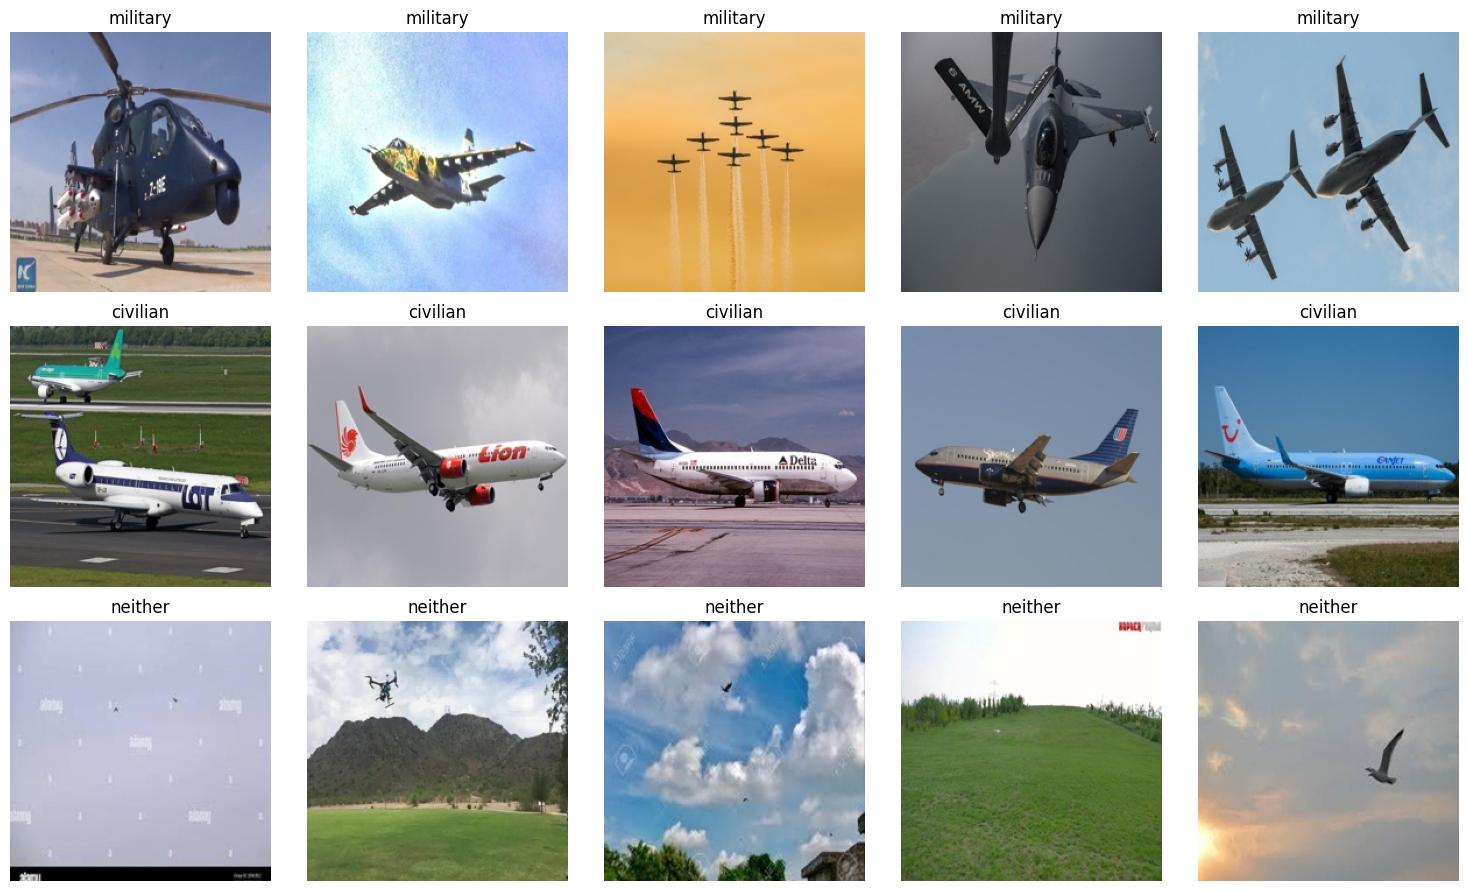

In [6]:
# How many sample images to show for each class
NUM_SAMPLES = 5

# Fixed seed so the same sample images are shown every time
rng = random.Random(0)

# Make a grid of pictures: one row per class, NUM_SAMPLES pictures per row
fig, axes = plt.subplots(len(CLASSES), NUM_SAMPLES, figsize=(3 * NUM_SAMPLES, 3 * len(CLASSES)))

for row, label in enumerate(CLASSES):
    # All training images of this class
    folder = os.path.join(processed_dir, "train", label)
    filenames = sorted(os.listdir(folder))

    # Pick a few at random
    picked = rng.sample(filenames, NUM_SAMPLES)

    for col, filename in enumerate(picked):
        img = Image.open(os.path.join(folder, filename))
        ax = axes[row][col]
        ax.imshow(img)
        ax.set_title(label)
        ax.axis("off")  # hide the x/y axis numbers

plt.tight_layout()
plt.show()